In [8]:
import tensorflow_hub as hub # to download the ready-trained model
import tensorflow as tf # the deep-learning engine
import numpy as np # for working with number arrays
import cv2 # OpenCV: open images, draw boxes
from google.colab import files
from google.colab.patches import cv2_imshow # Colab’s replacement for cv2.imshow

In [9]:
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL)

In [10]:
COCO_CLASSES = ["person", "bicycle", "car", "motorcycle", "airplane", "bus",
 "train", "truck", "boat", "traffic light", "fire hydrant", "stop sign",
 "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
"scissors", "teddy bear", "hair drier", "toothbrush"]

def detect_objects_with_boxes(image_path, detector):
  """Run the detector on one image and return the image with boxes drawn."""
  image = cv2.imread(image_path) # read image (BGR pixels)
  orig_image = image.copy() # clean copy to draw on

  input_tensor = tf.convert_to_tensor(image) # image → tensor
  input_tensor = input_tensor[tf.newaxis, ...] # add batch axis: "here is 1 photo"

  detections = detector(input_tensor) # one forward pass

  num_detections = int(detections["num_detections"])
  detection_boxes = detections["detection_boxes"].numpy()[0] # WHERE (fractions)
  detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32) # WHAT
  detection_scores = detections["detection_scores"].numpy()[0] # HOW SURE

  confidence_threshold = 0.5 # ignore boxes below 50% sure
  for i in range(num_detections):
    score=detection_scores[i]
    if score > confidence_threshold:
      box=detection_boxes[i]
      h,w,_=orig_image.shape
      y_min, x_min, y_max, x_max = box # note: y comes first
      x_min, x_max = int(x_min * w), int(x_max * w) # fractions → pixels
      y_min, y_max = int(y_min * h), int(y_max * h)
      class_id = detection_classes[i]
      class_name = COCO_CLASSES[class_id - 1] if 1 <= class_id <= 80 else "Unknown"
      label = f"{class_name}: {score:.2f}"
      cv2.rectangle(orig_image, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
      cv2.putText(orig_image, label, (x_min, y_min - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
  return orig_image


Saving sample image.jpg to sample image.jpg


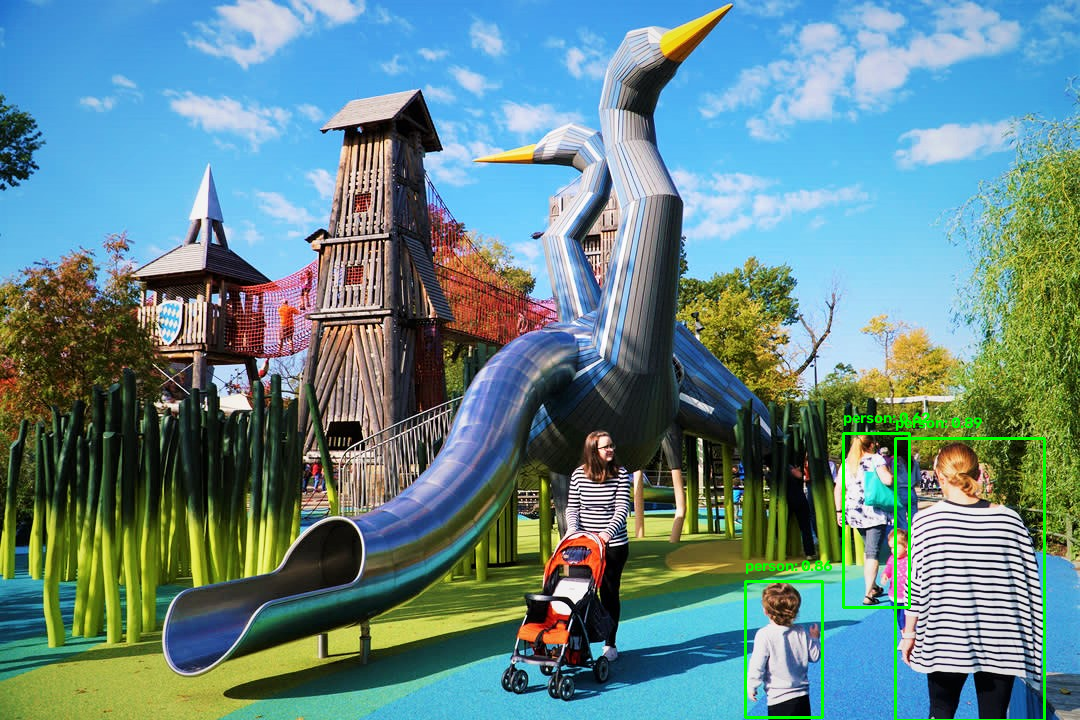

In [11]:
uploaded = files.upload() # "Choose Files" button in the browser
image_path = next(iter(uploaded)) # the file the user picked
result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image) # show in Colab (NOT cv2.imshow)